# **1. Accéssion aux données (montage du Drive et définition du chemin)**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
chemin = "/content/drive/MyDrive/Mémoire_Master_Dataset/CICIDS2017"

import os
print(os.listdir(chemin))

Mounted at /content/drive
['Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv', 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv', 'Friday-WorkingHours-Morning.pcap_ISCX.csv', 'Monday-WorkingHours.pcap_ISCX.csv', 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv', 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv', 'Tuesday-WorkingHours.pcap_ISCX.csv', 'Wednesday-workingHours.pcap_ISCX.csv']


# **2. Définir les fonctions de chargement**

In [ ]:
import glob
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

In [ ]:
def charger_cicids2017(dossier):
    """Lit tous les CSV du dossier (sous-dossiers compris), nettoie et renvoie un DataFrame."""
    fichiers = sorted(glob.glob(os.path.join(dossier, "**", "*.csv"), recursive=True))
    if not fichiers:
        raise FileNotFoundError(f"Aucun fichier .csv trouvé dans {dossier}")
    print(f"{len(fichiers)} fichiers trouvés :")

    morceaux = []
    for f in fichiers:
        # Ces fichiers contiennent un caractère non UTF-8 dans certains libellés
        d = pd.read_csv(f, encoding="latin-1", low_memory=False)
        d.columns = d.columns.str.strip()          # noms de colonnes avec espaces parasites
        if "Label" not in d.columns:
            raise ValueError(f"Colonne 'Label' absente dans {os.path.basename(f)}")
        print(f"  {os.path.basename(f):<60}{len(d):>9} lignes")
        morceaux.append(d)
    df = pd.concat(morceaux, ignore_index=True)
    n0 = len(df)

    # Libellés : on retire les caractères non ASCII (tiret long mal encodé)
    df["Label"] = (df["Label"].astype(str)
                   .str.replace(r"[^\x20-\x7E]+", "-", regex=True)
                   .str.replace(r"\s*-\s*", " - ", regex=True)
                   .str.strip())

    colonnes = [c for c in df.columns if c != "Label"]
    df[colonnes] = df[colonnes].apply(pd.to_numeric, errors="coerce")

    # Valeurs infinies (Flow Bytes/s, Flow Packets/s) -> manquantes, puis suppression
    df[colonnes] = df[colonnes].replace([np.inf, -np.inf], np.nan)
    n_nan = int(df[colonnes].isna().any(axis=1).sum())
    df = df.dropna(subset=colonnes)

    # Doublons exacts (nombreux dans ce jeu)
    n_avant = len(df)
    df = df.drop_duplicates()
    n_dup = n_avant - len(df)

    # Colonnes constantes (aucune information)
    constantes = [c for c in colonnes if df[c].nunique() <= 1]
    df = df.drop(columns=constantes)

    df[[c for c in df.columns if c != "Label"]] = \
        df[[c for c in df.columns if c != "Label"]].astype("float32")
    df = df.reset_index(drop=True)

    print(f"\nLignes lues : {n0} | avec valeurs manquantes/infinies retirées : {n_nan} "
          f"| doublons retirés : {n_dup} | colonnes constantes retirées : {len(constantes)}")
    print(f"Lignes finales : {len(df)} | caractéristiques : {df.shape[1] - 1}")
    print("\nRépartition des classes :")
    print(df["Label"].value_counts())
    return df

In [ ]:
def _log_signe(x):
    """Compression des valeurs très étalées, en gardant le signe (certaines colonnes sont négatives)."""
    return np.sign(x) * np.log1p(np.abs(x))

In [ ]:
def preparer(df, graine=0, frac_train=0.6, frac_val=0.2,
             max_benins=None, max_attaques=None):
    """
    Protocole : le trafic BENIGN est séparé en entraînement / validation / test ;
    toutes les attaques vont uniquement dans le test. Le seuil se règle sur la
    validation (jamais sur le test), l'échelle est apprise sur l'entraînement seul.
    """
    rng = np.random.default_rng(graine)
    cols = [c for c in df.columns if c != "Label"]
    est_benin = (df["Label"] == "BENIGN").values

    idx_b = rng.permutation(np.where(est_benin)[0])
    idx_a = rng.permutation(np.where(~est_benin)[0])
    if max_benins:
        idx_b = idx_b[:max_benins]
    if max_attaques:
        idx_a = idx_a[:max_attaques]

    n = len(idx_b)
    n_tr, n_va = int(frac_train * n), int(frac_val * n)
    i_tr, i_va, i_te_b = idx_b[:n_tr], idx_b[n_tr:n_tr + n_va], idx_b[n_tr + n_va:]
    i_test = np.concatenate([i_te_b, idx_a])

    X = df[cols].values
    Xl = _log_signe(X)
    sc = MinMaxScaler().fit(Xl[i_tr])           # échelle apprise sur le normal d'entraînement
    f = lambda idx: sc.transform(Xl[idx]).astype("float32")

    y_test = np.concatenate([np.zeros(len(i_te_b), int), np.ones(len(idx_a), int)])
    types_test = np.concatenate([df["Label"].values[i_te_b], df["Label"].values[idx_a]])

    donnees = {
        "X_train_normal": f(i_tr),
        "X_val_normal": f(i_va),
        "X_test": f(i_test),
        "y_test": y_test,
        "types_test": types_test,
        "colonnes": cols,
        "scaler": sc,
    }
    print(f"\nEntraînement (normal) : {len(i_tr)} | validation (normal) : {len(i_va)} "
          f"| test : {len(i_test)} dont {int(y_test.sum())} attaques "
          f"({100 * y_test.mean():.1f} %)")
    return donnees

# **3. Charger et préparer les données**

In [ ]:
df = charger_cicids2017(chemin)
d = preparer(df, graine=0, max_benins=300_000, max_attaques=150_000)

8 fichiers trouvés :
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv               225745 lignes
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv           286467 lignes
  Friday-WorkingHours-Morning.pcap_ISCX.csv                      191033 lignes
  Monday-WorkingHours.pcap_ISCX.csv                              529918 lignes
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv    288602 lignes
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv         170366 lignes
  Tuesday-WorkingHours.pcap_ISCX.csv                             445909 lignes
  Wednesday-workingHours.pcap_ISCX.csv                           692703 lignes

Lignes lues : 2830743 | avec valeurs manquantes/infinies retirées : 2867 | doublons retirés : 307078 | colonnes constantes retirées : 8
Lignes finales : 2520798 | caractéristiques : 70

Répartition des classes :
Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan      

# **4. Sauvegarder les données préparées (cellule ajoutée avant la baseline)**

In [ ]:
# Gardons les données préparées sur le Drive, pour ne pas tout recharger la prochaine fois
import numpy as np

dossier_sortie = "/content/drive/MyDrive/Mémoire_Master_Dataset/donnees_pretes.npz"
np.savez_compressed(dossier_sortie,
                    X_train_normal=d["X_train_normal"],
                    X_val_normal=d["X_val_normal"],
                    X_test=d["X_test"],
                    y_test=d["y_test"],
                    types_test=d["types_test"])
print("Sauvegardé dans", dossier_sortie)

Sauvegardé dans /content/drive/MyDrive/Mémoire_Master_Dataset/donnees_pretes.npz


# **5. Rechargons d’abord les données sauvegardées**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
f = np.load("/content/drive/MyDrive/Mémoire_Master_Dataset/donnees_pretes.npz", allow_pickle=True)
d = {cle: f[cle] for cle in f.files}
print({cle: d[cle].shape for cle in d})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'X_train_normal': (180000, 70), 'X_val_normal': (60000, 70), 'X_test': (210000, 70), 'y_test': (210000,), 'types_test': (210000,)}


# **6. L'Entraînement de la baseline (autoencodeur) et les Résultats**

 **6.1. Importation des bibliothèque**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)

np.random.seed(0)
tf.random.set_seed(0)

In [ ]:
# les données préparées à l'étape 3
X_train = d["X_train_normal"]
X_val = d["X_val_normal"]
X_test = d["X_test"]
y_test = d["y_test"]
types = d["types_test"]
nb_col = X_train.shape[1]
print("Nombre de caractéristiques :", nb_col)

Nombre de caractéristiques : 70


In [ ]:
# l'autoencodeur : il compresse chaque flux en 16 valeurs, puis essaie de le reconstruire
entree = keras.Input(shape=(nb_col,))
x = layers.Dense(64, activation="relu")(entree)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(16, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
x = layers.Dense(64, activation="relu")(x)
sortie = layers.Dense(nb_col, activation="linear")(x)
modele = keras.Model(entree, sortie)
modele.compile(optimizer="adam", loss="mse")

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.0149 - val_loss: 0.0027
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.0020 - val_loss: 0.0015
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0013 - val_loss: 0.0011
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0010 - val_loss: 9.2378e-04
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 8.4941e-04 - val_loss: 7.8801e-04
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 7.3224e-04 - val_loss: 7.0172e-04
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 6.5678e-04 - val_loss: 6.4261e-04
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 5.9696e-04 - val_loss: 6.0632e-04
Epoch 9/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 5.4925e-04 - val_loss: 5.5922e-04
Epoch 10/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 5.1283e-04 - val_loss: 5.3162e-04
Epoch 11/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 4.8425e-04 - val_loss: 4.9

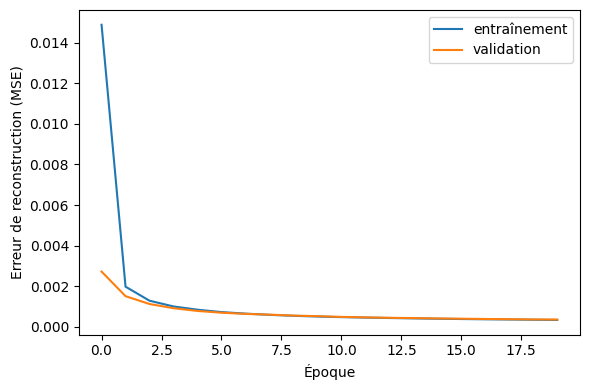

In [ ]:
# on l'entraîne seulement sur du trafic normal
histo = modele.fit(X_train, X_train, epochs=20, batch_size=256,
                   validation_data=(X_val, X_val), verbose=1)

plt.figure(figsize=(6, 4))
plt.plot(histo.history["loss"], label="entraînement")
plt.plot(histo.history["val_loss"], label="validation")
plt.xlabel("Époque")
plt.ylabel("Erreur de reconstruction (MSE)")
plt.legend()
plt.tight_layout()
plt.savefig("courbe_apprentissage.png", dpi=150)
plt.show()

In [ ]:

# l'erreur de reconstruction de chaque flux : plus elle est grande, plus le flux paraît "bizarre"
def erreur(X):
    reconstruit = modele.predict(X, batch_size=4096, verbose=0)
    return np.mean((X - reconstruit) ** 2, axis=1)

In [ ]:
# le seuil se fixe sur la validation (trafic normal) : on laisse 5 % de faux positifs
seuil = np.percentile(erreur(X_val), 95)
print("\nSeuil :", seuil)


Seuil : 0.0011510914


In [ ]:
# l'évaluation sur le test
err_test = erreur(X_test)
y_pred = (err_test > seuil).astype(int)

print("\n--- Résultats de la baseline (avant attaque) ---")
print("Précision :", round(precision_score(y_test, y_pred), 4))
print("Rappel    :", round(recall_score(y_test, y_pred), 4))
print("F1-score  :", round(f1_score(y_test, y_pred), 4))
auc = roc_auc_score(y_test, err_test)
print("AUC       :", round(auc, 4))


--- Résultats de la baseline (avant attaque) ---
Précision : 0.9726
Rappel    : 0.695
F1-score  : 0.8107
AUC       : 0.9374


In [ ]:
# Le rappel pour chaque type d'attaque : lesquelles détecte-t-on bien ?
tableau = pd.DataFrame({"type": types, "detecte": y_pred})
tableau = tableau[tableau["type"] != "BENIGN"]
tableau = tableau.groupby("type")["detecte"].agg(["mean", "size"])
tableau.columns = ["rappel", "effectif"]
print("\nRappel par type d'attaque :")
print(tableau.sort_values("effectif", ascending=False).round(3).to_string())


Rappel par type d'attaque :
                            rappel  effectif
type                                        
DoS Hulk                     0.864     60939
DDoS                         0.895     45055
PortScan                     0.124     31858
DoS GoldenEye                0.812      3663
FTP - Patator                0.144      2109
DoS slowloris                0.983      1905
DoS Slowhttptest             0.997      1843
SSH - Patator                0.009      1168
Bot                          0.443       686
Web Attack - Brute Force     0.053       526
Web Attack - XSS             0.036       221
Infiltration                 0.818        11
Web Attack - Sql Injection   0.000         9
Heartbleed                   1.000         7



Matrice de confusion :
 [[ 57059   2941]
 [ 45748 104252]]


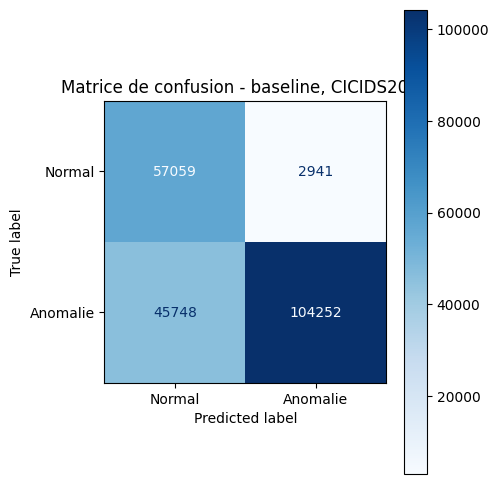

In [ ]:
# La Matrice de Confusion
cm = confusion_matrix(y_test, y_pred)
print("\nMatrice de confusion :\n", cm)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomalie"]).plot(
    ax=ax, cmap="Blues", values_format="d")
plt.title("Matrice de confusion - baseline, CICIDS2017")
plt.tight_layout()
plt.savefig("matrice_confusion_baseline_cicids.png", dpi=150)
plt.show()


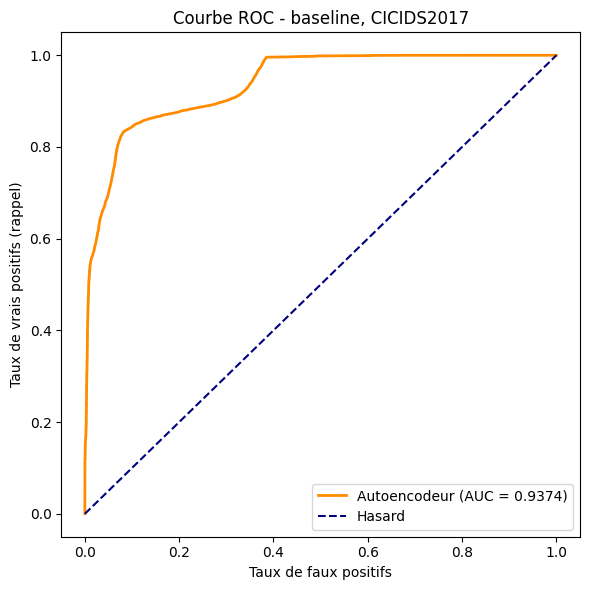

In [ ]:
# La courbe ROC
fpr, tpr, _ = roc_curve(y_test, err_test)
plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Autoencodeur (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="navy", label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (rappel)")
plt.title("Courbe ROC - baseline, CICIDS2017")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("courbe_roc_baseline_cicids.png", dpi=150)
plt.show()

# **Sauvegardage du modèle entraîné et le seuil, pour réutilise exactement la même baseline**

In [ ]:
# on garde le modèle et le seuil pour la suite (attaques, défenses)
dossier = "/content/drive/MyDrive/Mémoire_Master_Dataset/"
modele.save(dossier + "baseline_autoencodeur.keras")
np.save(dossier + "seuil_baseline.npy", seuil)
print("Modèle et seuil sauvegardés")

Modèle et seuil sauvegardés


# **Le code ci-dessous est l’étape des attaques FGSM et PGD sur CICIDS2017.**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

In [ ]:

# --- 1. on recharge tout ce qu'on a sauvegardé (baseline + données) ---
dossier = "/content/drive/MyDrive/Mémoire_Master_Dataset/"
modele = keras.models.load_model(dossier + "baseline_autoencodeur.keras", compile=False)
seuil = float(np.load(dossier + "seuil_baseline.npy"))

f = np.load(dossier + "donnees_pretes.npz", allow_pickle=True)
X_test = f["X_test"]
y_test = f["y_test"]
types = f["types_test"]

X_benin = X_test[y_test == 0]
X_att = X_test[y_test == 1]
types_att = types[y_test == 1]
print("Flux normaux :", len(X_benin), "| attaques :", len(X_att))


def erreur(X):
    rec = modele.predict(X, batch_size=4096, verbose=0)
    return np.mean((X - rec) ** 2, axis=1)


err_benin = erreur(X_benin)
err_att = erreur(X_att)
detectee_avant = err_att > seuil
print("Rappel avant attaque :", round(detectee_avant.mean(), 4))

Flux normaux : 60000 | attaques : 150000
Rappel avant attaque : 0.695


In [ ]:
# --- 2. les attaques ---
# L'attaquant veut que l'erreur de reconstruction de son flux DIMINUE :
# on avance donc dans le sens contraire du gradient de l'erreur.
@tf.function
def signe_gradient(x):
    with tf.GradientTape() as tape:
        tape.watch(x)
        err = tf.reduce_mean(tf.square(x - modele(x, training=False)), axis=1)
        perte = tf.reduce_sum(err)
    return tf.sign(tape.gradient(perte, x))


def attaquer(X, eps, methode, n_iter=10, taille=8192):
    """FGSM = un seul pas de taille eps. PGD = plusieurs petits pas, toujours à moins de eps de l'original."""
    alpha = eps / 4
    resultat = []
    for i in range(0, len(X), taille):
        x = tf.constant(X[i:i + taille])
        # on ne sort pas de [0, 1], sauf si la valeur de départ y était déjà
        bas = tf.minimum(x, 0.0)
        haut = tf.maximum(x, 1.0)
        x_adv = x
        if methode == "fgsm":
            x_adv = x_adv - eps * signe_gradient(x_adv)
            x_adv = tf.clip_by_value(x_adv, bas, haut)
        else:
            for _ in range(n_iter):
                x_adv = x_adv - alpha * signe_gradient(x_adv)
                x_adv = tf.clip_by_value(x_adv, x - eps, x + eps)
                x_adv = tf.clip_by_value(x_adv, bas, haut)
        resultat.append(x_adv.numpy())
    return np.concatenate(resultat)


def mesures(err_a):
    """Rappel, AUC et rappel sur les attaques que la baseline détectait déjà."""
    rappel = (err_a > seuil).mean()
    rappel_detectables = (err_a[detectee_avant] > seuil).mean()
    auc = roc_auc_score(np.r_[np.zeros(len(err_benin)), np.ones(len(err_a))],
                        np.r_[err_benin, err_a])
    return rappel, rappel_detectables, auc

In [ ]:
# --- 3. l'effet de epsilon ---
lignes = [("aucune", 0.0, *mesures(err_att))]
for eps in [0.01, 0.02, 0.05, 0.10]:
    for methode in ["fgsm", "pgd"]:
        X_adv = attaquer(X_att, eps, methode)
        lignes.append((methode.upper(), eps, *mesures(erreur(X_adv))))

tab = pd.DataFrame(lignes, columns=["attaque", "epsilon", "rappel", "rappel_detectables", "AUC"])
print("\nEffet de epsilon (seuil de la baseline, rappel_detectables = attaques déjà vues par la baseline) :")
print(tab.round(4).to_string(index=False))


Effet de epsilon (seuil de la baseline, rappel_detectables = attaques déjà vues par la baseline) :
attaque  epsilon  rappel  rappel_detectables    AUC
 aucune     0.00  0.6950              1.0000 0.9374
   FGSM     0.01  0.6364              0.9156 0.9129
    PGD     0.01  0.6266              0.9015 0.8971
   FGSM     0.02  0.6333              0.9056 0.9402
    PGD     0.02  0.5780              0.8317 0.8777
   FGSM     0.05  0.9964              0.9999 0.9889
    PGD     0.05  0.5056              0.7267 0.9075
   FGSM     0.10  1.0000              1.0000 0.9976
    PGD     0.10  0.7547              0.8106 0.9613


In [ ]:
# --- 4. analyse détaillée pour un epsilon choisi ---
EPS = 0.05
X_fgsm = attaquer(X_att, EPS, "fgsm")
X_pgd = attaquer(X_att, EPS, "pgd")
err_fgsm = erreur(X_fgsm)
err_pgd = erreur(X_pgd)

In [ ]:
# Le rappel par type d'attaque : avant / FGSM / PGD
par_type = pd.DataFrame({"type": types_att,
                         "avant": err_att > seuil,
                         "FGSM": err_fgsm > seuil,
                         "PGD": err_pgd > seuil})
par_type = par_type.groupby("type").agg(effectif=("avant", "size"),
                                        avant=("avant", "mean"),
                                        FGSM=("FGSM", "mean"),
                                        PGD=("PGD", "mean"))
print(f"\nRappel par type d'attaque (epsilon = {EPS}) :")
print(par_type.sort_values("effectif", ascending=False).round(3).to_string())


Rappel par type d'attaque (epsilon = 0.05) :
                            effectif  avant   FGSM    PGD
type                                                     
DoS Hulk                       60939  0.864  0.992  0.836
DDoS                           45055  0.895  1.000  0.448
PortScan                       31858  0.124  1.000  0.006
DoS GoldenEye                   3663  0.812  0.998  0.277
FTP - Patator                   2109  0.144  0.994  0.000
DoS slowloris                   1905  0.983  1.000  0.952
DoS Slowhttptest                1843  0.997  0.999  0.903
SSH - Patator                   1168  0.009  0.996  0.000
Bot                              686  0.443  1.000  0.003
Web Attack - Brute Force         526  0.053  1.000  0.000
Web Attack - XSS                 221  0.036  1.000  0.000
Infiltration                      11  0.818  1.000  0.636
Web Attack - Sql Injection         9  0.000  1.000  0.000
Heartbleed                         7  1.000  1.000  1.000



Matrice de confusion sous FGSM :
 [[ 57059   2941]
 [   543 149457]]

Matrice de confusion sous PGD :
 [[57059  2941]
 [74165 75835]]


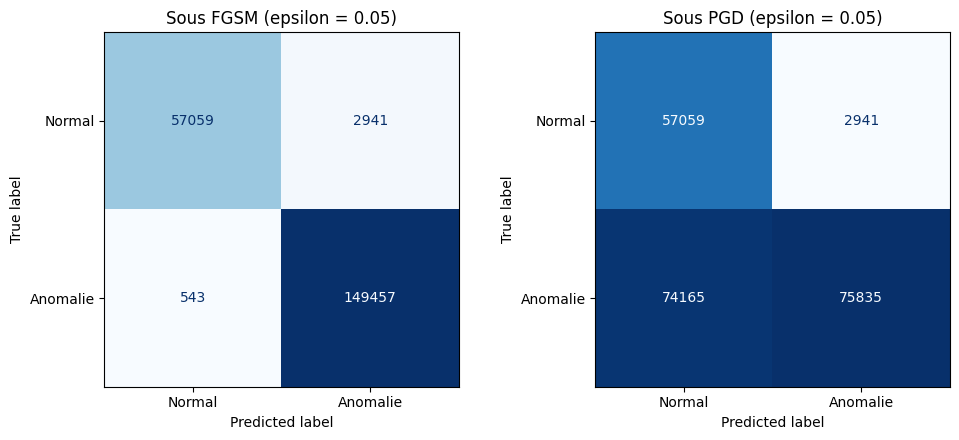

In [ ]:
# La matrices de confusion : normaux inchangés + attaques perturbées
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, nom, err_a in zip(axes, ["FGSM", "PGD"], [err_fgsm, err_pgd]):
    pred = np.r_[err_benin > seuil, err_a > seuil].astype(int)
    vrai = np.r_[np.zeros(len(err_benin)), np.ones(len(err_a))]
    cm = confusion_matrix(vrai, pred)
    print(f"\nMatrice de confusion sous {nom} :\n", cm)
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomalie"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Sous {nom} (epsilon = {EPS})")
plt.tight_layout()
plt.savefig("matrices_confusion_attaques_cicids.png", dpi=150)
plt.show()

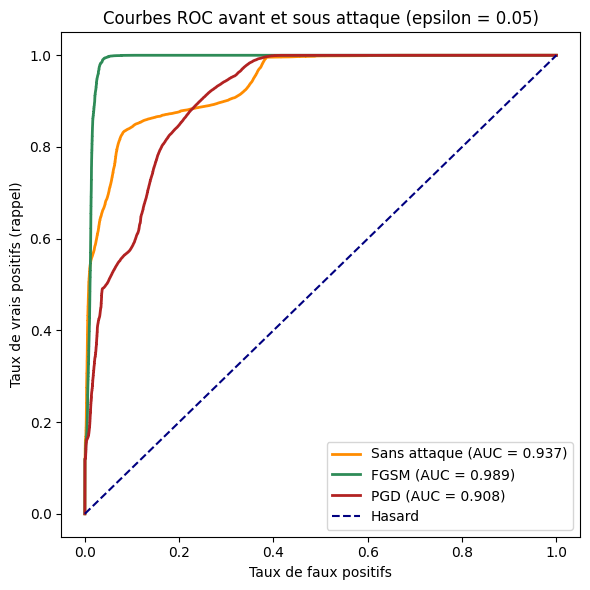

In [ ]:
# La courbes ROC : sans attaque, FGSM, PGD
vrai = np.r_[np.zeros(len(err_benin)), np.ones(len(err_att))]
plt.figure(figsize=(6, 6))
for nom, err_a, couleur in [("Sans attaque", err_att, "darkorange"),
                            ("FGSM", err_fgsm, "seagreen"),
                            ("PGD", err_pgd, "firebrick")]:
    fpr, tpr, _ = roc_curve(vrai, np.r_[err_benin, err_a])
    auc = roc_auc_score(vrai, np.r_[err_benin, err_a])
    plt.plot(fpr, tpr, color=couleur, lw=2, label=f"{nom} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="navy", label="Hasard")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs (rappel)")
plt.title(f"Courbes ROC avant et sous attaque (epsilon = {EPS})")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_attaques_cicids.png", dpi=150)
plt.show()



#  **Entraînement de la baseline sur 10 graines**



In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/Mémoire_Master_Dataset/donnees_pretes.npz"))

True


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score

In [ ]:
dossier = "/content/drive/MyDrive/Mémoire_Master_Dataset/"
NB_GRAINES = 10          # Le nombre d'entraînements indépendants
EPOQUES = 20
EPS_FGSM = [0.02, 0.05]
EPS_PGD = [0.02, 0.05, 0.10]
EPS_DETAIL = 0.05        # epsilon utilisé pour le détail par type d'attaque

# --- données (le découpage est celui de l'étape 3, il ne change pas d'une graine à l'autre) ---
f = np.load(dossier + "donnees_pretes.npz", allow_pickle=True)
X_train, X_val = f["X_train_normal"], f["X_val_normal"]
X_test, y_test, types = f["X_test"], f["y_test"], f["types_test"]
X_benin = X_test[y_test == 0]
X_att = X_test[y_test == 1]
types_att = types[y_test == 1]
nb_col = X_train.shape[1]

In [ ]:

def construire_modele():
    entree = keras.Input(shape=(nb_col,))
    x = layers.Dense(64, activation="relu")(entree)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dense(16, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(x)
    sortie = layers.Dense(nb_col, activation="linear")(x)
    m = keras.Model(entree, sortie)
    m.compile(optimizer="adam", loss="mse")
    return m

In [ ]:

def fabriquer_outils(modele):
    """Les fonctions d'attaque sont recréées pour chaque modèle (sinon TensorFlow garde l'ancien)."""

    @tf.function
    def err_tf(x):
        return tf.reduce_mean(tf.square(x - modele(x, training=False)), axis=1)

    @tf.function
    def signe_gradient(x):
        with tf.GradientTape() as tape:
            tape.watch(x)
            perte = tf.reduce_sum(err_tf(x))
        return tf.sign(tape.gradient(perte, x))

    def erreur(X):
        return np.mean((X - modele.predict(X, batch_size=4096, verbose=0)) ** 2, axis=1)

    def fgsm(X, eps, taille=8192):
        sortie = []
        for i in range(0, len(X), taille):
            x = tf.constant(X[i:i + taille])
            x_adv = x - eps * signe_gradient(x)
            sortie.append(tf.clip_by_value(x_adv, tf.minimum(x, 0.0), tf.maximum(x, 1.0)).numpy())
        return np.concatenate(sortie)

    def pgd(X, eps, alpha=0.005, n_iter=40, taille=8192):
        """Petits pas fixes ; pour chaque flux on garde la meilleure version trouvée (erreur la plus basse)."""
        sortie = []
        for i in range(0, len(X), taille):
            x = tf.constant(X[i:i + taille])
            bas, haut = tf.minimum(x, 0.0), tf.maximum(x, 1.0)
            x_adv = x
            meilleur, meilleure_err = x, err_tf(x)
            for _ in range(n_iter):
                x_adv = x_adv - alpha * signe_gradient(x_adv)
                x_adv = tf.clip_by_value(x_adv, x - eps, x + eps)
                x_adv = tf.clip_by_value(x_adv, bas, haut)
                e = err_tf(x_adv)
                mieux = e < meilleure_err
                meilleur = tf.where(mieux[:, None], x_adv, meilleur)
                meilleure_err = tf.where(mieux, e, meilleure_err)
            sortie.append(meilleur.numpy())
        return np.concatenate(sortie)

    return erreur, fgsm, pgd

In [ ]:

def auc(err_b, err_a):
    return roc_auc_score(np.r_[np.zeros(len(err_b)), np.ones(len(err_a))], np.r_[err_b, err_a])

In [ ]:

# --- reprise automatique : si Colab s'est coupé, on repart des graines déjà faites ---
f_global = dossier + "resultats_graines_global.csv"
f_types = dossier + "resultats_graines_types.csv"
lignes = pd.read_csv(f_global).to_dict("records") if os.path.exists(f_global) else []
lignes_types = pd.read_csv(f_types).to_dict("records") if os.path.exists(f_types) else []
deja = {int(l["graine"]) for l in lignes}
print("Graines déjà faites :", sorted(deja))

for graine in range(NB_GRAINES):
    if graine in deja:
        continue
    keras.backend.clear_session()
    keras.utils.set_random_seed(graine)
    modele = construire_modele()
    modele.fit(X_train, X_train, epochs=EPOQUES, batch_size=256,
               validation_data=(X_val, X_val), verbose=0)
    erreur, fgsm, pgd = fabriquer_outils(modele)

    seuil = np.percentile(erreur(X_val), 95)
    err_b, err_a = erreur(X_benin), erreur(X_att)
    detectee = err_a > seuil
    ligne = {"graine": graine,
             "faux_positifs": (err_b > seuil).mean(),
             "rappel_propre": detectee.mean(),
             "auc_propre": auc(err_b, err_a)}

    for eps in EPS_FGSM:
        ligne[f"rappel_fgsm_{eps}"] = (erreur(fgsm(X_att, eps)) > seuil).mean()
    for eps in EPS_PGD:
        e_adv = erreur(pgd(X_att, eps))
        ligne[f"rappel_pgd_{eps}"] = (e_adv > seuil).mean()
        ligne[f"rappel_pgd_{eps}_detectables"] = (e_adv[detectee] > seuil).mean()
        ligne[f"auc_pgd_{eps}"] = auc(err_b, e_adv)
        if eps == EPS_DETAIL:
            e_detail = e_adv
    lignes.append(ligne)

    d = pd.DataFrame({"type": types_att, "propre": err_a > seuil, "pgd": e_detail > seuil})
    for t, g in d.groupby("type"):
        lignes_types.append({"graine": graine, "type": t,
                             "rappel_propre": g["propre"].mean(), "rappel_pgd": g["pgd"].mean()})

    # sauvegarde après chaque graine
    pd.DataFrame(lignes).to_csv(f_global, index=False)
    pd.DataFrame(lignes_types).to_csv(f_types, index=False)
    print(f"graine {graine} terminée | rappel propre {ligne['rappel_propre']:.3f} "
          f"| rappel PGD {EPS_DETAIL} : {ligne[f'rappel_pgd_{EPS_DETAIL}']:.3f}")

Graines déjà faites : []
graine 0 terminée | rappel propre 0.709 | rappel PGD 0.05 : 0.422
graine 1 terminée | rappel propre 0.720 | rappel PGD 0.05 : 0.388
graine 2 terminée | rappel propre 0.786 | rappel PGD 0.05 : 0.421
graine 3 terminée | rappel propre 0.802 | rappel PGD 0.05 : 0.446
graine 4 terminée | rappel propre 0.755 | rappel PGD 0.05 : 0.462
graine 5 terminée | rappel propre 0.635 | rappel PGD 0.05 : 0.413
graine 6 terminée | rappel propre 0.772 | rappel PGD 0.05 : 0.441
graine 7 terminée | rappel propre 0.718 | rappel PGD 0.05 : 0.422
graine 8 terminée | rappel propre 0.793 | rappel PGD 0.05 : 0.483
graine 9 terminée | rappel propre 0.793 | rappel PGD 0.05 : 0.491


In [ ]:

# --- résumé : moyenne ± écart-type sur toutes les graines ---
g = pd.DataFrame(lignes).drop(columns="graine")
resume = pd.DataFrame({"moyenne": g.mean(), "ecart_type": g.std(ddof=1)})
print(f"\n=== Résumé sur {len(g)} graines ===")
print(resume.round(4).to_string())

gt = pd.DataFrame(lignes_types)
effectifs = pd.Series(types_att).value_counts()
par_type = gt.groupby("type").agg(rappel_propre=("rappel_propre", "mean"),
                                  ecart_propre=("rappel_propre", lambda s: s.std(ddof=1)),
                                  rappel_pgd=("rappel_pgd", "mean"),
                                  ecart_pgd=("rappel_pgd", lambda s: s.std(ddof=1)))
par_type["effectif"] = effectifs
print(f"\n=== Rappel par type d'attaque (PGD, epsilon = {EPS_DETAIL}) ===")
print(par_type.sort_values("effectif", ascending=False).round(3).to_string())




=== Résumé sur 10 graines ===
                             moyenne  ecart_type
faux_positifs                 0.0490      0.0009
rappel_propre                 0.7484      0.0526
auc_propre                    0.9484      0.0101
rappel_fgsm_0.02              0.6110      0.0899
rappel_fgsm_0.05              0.9318      0.0865
rappel_pgd_0.02               0.5559      0.0513
rappel_pgd_0.02_detectables   0.7428      0.0440
auc_pgd_0.02                  0.8879      0.0222
rappel_pgd_0.05               0.4390      0.0324
rappel_pgd_0.05_detectables   0.5876      0.0369
auc_pgd_0.05                  0.8061      0.0318
rappel_pgd_0.1                0.2498      0.0605
rappel_pgd_0.1_detectables    0.3347      0.0786
auc_pgd_0.1                   0.7007      0.0443

=== Rappel par type d'attaque (PGD, epsilon = 0.05) ===
                            rappel_propre  ecart_propre  rappel_pgd  ecart_pgd  effectif
type                                                                                    

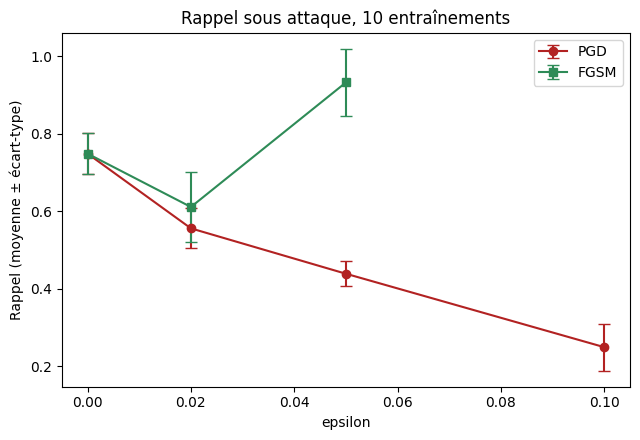

In [ ]:
# --- figure : rappel en fonction de epsilon (moyenne ± écart-type) ---
x_pgd = [0] + EPS_PGD
m_pgd = [g["rappel_propre"].mean()] + [g[f"rappel_pgd_{e}"].mean() for e in EPS_PGD]
s_pgd = [g["rappel_propre"].std(ddof=1)] + [g[f"rappel_pgd_{e}"].std(ddof=1) for e in EPS_PGD]
x_fg = [0] + EPS_FGSM
m_fg = [g["rappel_propre"].mean()] + [g[f"rappel_fgsm_{e}"].mean() for e in EPS_FGSM]
s_fg = [g["rappel_propre"].std(ddof=1)] + [g[f"rappel_fgsm_{e}"].std(ddof=1) for e in EPS_FGSM]

plt.figure(figsize=(6.5, 4.5))
plt.errorbar(x_pgd, m_pgd, yerr=s_pgd, marker="o", capsize=4, color="firebrick", label="PGD")
plt.errorbar(x_fg, m_fg, yerr=s_fg, marker="s", capsize=4, color="seagreen", label="FGSM")
plt.xlabel("epsilon")
plt.ylabel("Rappel (moyenne ± écart-type)")
plt.title(f"Rappel sous attaque, {len(g)} entraînements")
plt.legend()
plt.tight_layout()
plt.savefig("rappel_selon_epsilon_multigraines.png", dpi=150)
plt.show()

# **8. Entraînement du détecteur avec des exemples attaqués (entraînement adversarial, versions A et B) sur 10 graines, pour mesurer de combien le rappel sous PGD remonte par rapport à la baseline non défendue.**

In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/Mémoire_Master_Dataset/donnees_pretes.npz"))

True


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score

In [ ]:

dossier = "/content/drive/MyDrive/Mémoire_Master_Dataset/"
NB_GRAINES = 10
EPOQUES = 20
BATCH = 256
EPS_TRAIN = 0.05            # epsilon utilisé PENDANT l'entraînement des défenses
EPS_EVAL = [0.02, 0.05, 0.10]
LAMBDA = 1.0                # poids de la pénalité sur les attaques (défense B)
K_MARGE = 3.0               # marge = K_MARGE x seuil de la baseline (défense B)
NOMS = ["baseline", "defense_A", "defense_B"]

In [ ]:
# --- données ---
f = np.load(dossier + "donnees_pretes.npz", allow_pickle=True)
X_train, X_val = f["X_train_normal"], f["X_val_normal"]
X_test, y_test, types = f["X_test"], f["y_test"], f["types_test"]
X_benin = X_test[y_test == 0]
X_att_tout = X_test[y_test == 1]
types_tout = types[y_test == 1]
nb_col = X_train.shape[1]

In [ ]:
# on coupe les attaques en deux moitiés (par type) : une pour entraîner la défense B,
# l'autre pour évaluer TOUS les modèles. Le découpage est fixe.
rng0 = np.random.default_rng(0)
idx_tr, idx_ev = [], []
for t in np.unique(types_tout):
    idx = rng0.permutation(np.where(types_tout == t)[0])
    moitie = len(idx) // 2
    idx_tr += list(idx[:moitie])
    idx_ev += list(idx[moitie:])
X_att_train = X_att_tout[idx_tr]
X_att = X_att_tout[idx_ev]
types_att = types_tout[idx_ev]
print("Attaques pour entraîner B :", len(X_att_train), "| attaques pour évaluer :", len(X_att))

Attaques pour entraîner B : 74995 | attaques pour évaluer : 75005


In [ ]:
def construire_modele():
    entree = keras.Input(shape=(nb_col,))
    x = layers.Dense(64, activation="relu")(entree)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dense(16, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(x)
    sortie = layers.Dense(nb_col, activation="linear")(x)
    return keras.Model(entree, sortie)


def err_par_flux(modele, x):
    return tf.reduce_mean(tf.square(x - modele(x, training=False)), axis=1)


def pgd_tf(modele, x, eps, alpha, n_iter, signe):
    """signe = -1 : l'attaquant cherche à BAISSER l'erreur (évasion) ; +1 : à la MONTER."""
    bas, haut = tf.minimum(x, 0.0), tf.maximum(x, 1.0)
    x_adv = x
    for _ in range(n_iter):
        with tf.GradientTape() as tape:
            tape.watch(x_adv)
            perte = tf.reduce_sum(err_par_flux(modele, x_adv))
        g = tf.sign(tape.gradient(perte, x_adv))
        x_adv = x_adv + signe * alpha * g
        x_adv = tf.clip_by_value(x_adv, x - eps, x + eps)
        x_adv = tf.clip_by_value(x_adv, bas, haut)
    return tf.stop_gradient(x_adv)


def entrainer(variante, graine, marge=None):
    keras.backend.clear_session()
    keras.utils.set_random_seed(graine)
    modele = construire_modele()
    opt = keras.optimizers.Adam()

    def err_par_flux_train(x):
        return tf.reduce_mean(tf.square(x - modele(x, training=True)), axis=1)

    @tf.function
    def pas_A(xb):
        # défense A : on entraîne aussi sur des flux normaux rendus "plus suspects"
        x_adv = pgd_tf(modele, xb, EPS_TRAIN, EPS_TRAIN / 2, 3, +1.0)
        with tf.GradientTape() as tape:
            perte = 0.5 * tf.reduce_mean(err_par_flux_train(xb)) + 0.5 * tf.reduce_mean(err_par_flux_train(x_adv))
        opt.apply_gradients(zip(tape.gradient(perte, modele.trainable_variables), modele.trainable_variables))

    @tf.function
    def pas_B(xb, xa):
        # défense B : les attaques tentent de se cacher (PGD), et on pénalise celles qui y arrivent
        x_ev = pgd_tf(modele, xa, EPS_TRAIN, EPS_TRAIN / 2, 3, -1.0)
        with tf.GradientTape() as tape:
            perte_normal = tf.reduce_mean(err_par_flux_train(xb))
            perte_att = tf.reduce_mean(tf.nn.relu(marge - err_par_flux_train(x_ev)))
            perte = perte_normal + LAMBDA * perte_att
        opt.apply_gradients(zip(tape.gradient(perte, modele.trainable_variables), modele.trainable_variables))

    if variante == "baseline":
        modele.compile(optimizer="adam", loss="mse")
        modele.fit(X_train, X_train, epochs=EPOQUES, batch_size=BATCH, verbose=0)
        return modele

    rng = np.random.default_rng(graine)
    n = len(X_train)
    for _ in range(EPOQUES):
        ordre = rng.permutation(n)
        for i in range(0, n - BATCH + 1, BATCH):
            xb = tf.constant(X_train[ordre[i:i + BATCH]])
            if variante == "defense_A":
                pas_A(xb)
            else:
                xa = tf.constant(X_att_train[rng.integers(0, len(X_att_train), BATCH)])
                pas_B(xb, xa)
    return modele


def evaluer(modele):
    @tf.function
    def signe_gradient(x):
        with tf.GradientTape() as tape:
            tape.watch(x)
            perte = tf.reduce_sum(err_par_flux(modele, x))
        return tf.sign(tape.gradient(perte, x))

    def erreur(X):
        return np.mean((X - modele.predict(X, batch_size=4096, verbose=0)) ** 2, axis=1)

    def pgd(X, eps, alpha=0.005, n_iter=40, taille=8192):
        sortie = []
        for i in range(0, len(X), taille):
            x = tf.constant(X[i:i + taille])
            bas, haut = tf.minimum(x, 0.0), tf.maximum(x, 1.0)
            x_adv, meilleur, meilleure = x, x, err_par_flux(modele, x)
            for _ in range(n_iter):
                x_adv = x_adv - alpha * signe_gradient(x_adv)
                x_adv = tf.clip_by_value(x_adv, x - eps, x + eps)
                x_adv = tf.clip_by_value(x_adv, bas, haut)
                e = err_par_flux(modele, x_adv)
                mieux = e < meilleure
                meilleur = tf.where(mieux[:, None], x_adv, meilleur)
                meilleure = tf.where(mieux, e, meilleure)
            sortie.append(meilleur.numpy())
        return np.concatenate(sortie)

    def auc(eb, ea):
        return roc_auc_score(np.r_[np.zeros(len(eb)), np.ones(len(ea))], np.r_[eb, ea])

    seuil = np.percentile(erreur(X_val), 95)     # seuil recalculé pour CHAQUE modèle
    eb, ea = erreur(X_benin), erreur(X_att)
    res = {"seuil": seuil, "faux_positifs": (eb > seuil).mean(),
           "rappel_propre": (ea > seuil).mean(), "auc_propre": auc(eb, ea)}
    par_type = {}
    for eps in EPS_EVAL:
        e_adv = erreur(pgd(X_att, eps))
        res[f"rappel_pgd_{eps}"] = (e_adv > seuil).mean()
        res[f"auc_pgd_{eps}"] = auc(eb, e_adv)
        if eps == 0.05:
            par_type = pd.DataFrame({"type": types_att, "propre": ea > seuil, "pgd": e_adv > seuil})
    return res, par_type, seuil

In [ ]:

# --- reprise automatique ---
f_res = dossier + "resultats_defense.csv"
f_typ = dossier + "resultats_defense_types.csv"
lignes = pd.read_csv(f_res).to_dict("records") if os.path.exists(f_res) else []
lignes_types = pd.read_csv(f_typ).to_dict("records") if os.path.exists(f_typ) else []
deja = {int(l["graine"]) for l in lignes}
print("Graines déjà faites :", sorted(deja))

for graine in range(NB_GRAINES):
    if graine in deja:
        continue
    seuil_base = None
    for nom in NOMS:
        marge = K_MARGE * seuil_base if nom == "defense_B" else None
        modele = entrainer(nom, graine, marge)
        res, par_type, seuil = evaluer(modele)
        if nom == "baseline":
            seuil_base = seuil
        lignes.append({"graine": graine, "modele": nom, **res})
        for t, g in par_type.groupby("type"):
            lignes_types.append({"graine": graine, "modele": nom, "type": t,
                                 "rappel_propre": g["propre"].mean(), "rappel_pgd": g["pgd"].mean()})
        print(f"graine {graine} | {nom:<10} | propre {res['rappel_propre']:.3f} "
              f"| PGD 0.05 : {res['rappel_pgd_0.05']:.3f} | faux positifs {res['faux_positifs']:.3f}")
    pd.DataFrame(lignes).to_csv(f_res, index=False)
    pd.DataFrame(lignes_types).to_csv(f_typ, index=False)

Graines déjà faites : []
graine 0 | baseline   | propre 0.709 | PGD 0.05 : 0.422 | faux positifs 0.048
graine 0 | defense_A  | propre 0.579 | PGD 0.05 : 0.426 | faux positifs 0.049
graine 0 | defense_B  | propre 0.773 | PGD 0.05 : 0.707 | faux positifs 0.048
graine 1 | baseline   | propre 0.720 | PGD 0.05 : 0.389 | faux positifs 0.049
graine 1 | defense_A  | propre 0.536 | PGD 0.05 : 0.422 | faux positifs 0.047
graine 1 | defense_B  | propre 0.855 | PGD 0.05 : 0.808 | faux positifs 0.049
graine 2 | baseline   | propre 0.786 | PGD 0.05 : 0.421 | faux positifs 0.050
graine 2 | defense_A  | propre 0.646 | PGD 0.05 : 0.378 | faux positifs 0.049
graine 2 | defense_B  | propre 0.986 | PGD 0.05 : 0.977 | faux positifs 0.048
graine 3 | baseline   | propre 0.802 | PGD 0.05 : 0.446 | faux positifs 0.050
graine 3 | defense_A  | propre 0.684 | PGD 0.05 : 0.374 | faux positifs 0.048
graine 3 | defense_B  | propre 0.920 | PGD 0.05 : 0.826 | faux positifs 0.050
graine 4 | baseline   | propre 0.756 | 

In [ ]:
# --- résumé ---
df = pd.DataFrame(lignes)
cols = [c for c in df.columns if c not in ("graine", "modele", "seuil")]
moy = df.groupby("modele")[cols].mean().loc[NOMS]
std = df.groupby("modele")[cols].std(ddof=1).loc[NOMS]
print(f"\n=== Moyenne sur {df['graine'].nunique()} graines ===")
print(moy.round(3).T.to_string())
print("\n=== Écart-type ===")
print(std.round(3).T.to_string())


=== Moyenne sur 10 graines ===
modele           baseline  defense_A  defense_B
faux_positifs       0.049      0.049      0.049
rappel_propre       0.748      0.632      0.886
auc_propre          0.948      0.933      0.978
rappel_pgd_0.02     0.556      0.506      0.858
auc_pgd_0.02        0.888      0.867      0.972
rappel_pgd_0.05     0.439      0.424      0.820
auc_pgd_0.05        0.806      0.768      0.964
rappel_pgd_0.1      0.250      0.296      0.665
auc_pgd_0.1         0.701      0.629      0.936

=== Écart-type ===
modele           baseline  defense_A  defense_B
faux_positifs       0.001      0.001      0.001
rappel_propre       0.053      0.056      0.089
auc_propre          0.010      0.013      0.016
rappel_pgd_0.02     0.052      0.050      0.106
auc_pgd_0.02        0.022      0.022      0.018
rappel_pgd_0.05     0.032      0.038      0.136
auc_pgd_0.05        0.032      0.029      0.020
rappel_pgd_0.1      0.061      0.084      0.118
auc_pgd_0.1         0.044      0.039


=== Gain de la défense sur le rappel (différence avec la baseline, même graine) ===
defense_A | rappel_propre    | -0.117 ± 0.062 | meilleur que la baseline sur 0/10 graines
defense_A | rappel_pgd_0.02  | -0.050 ± 0.075 | meilleur que la baseline sur 2/10 graines
defense_A | rappel_pgd_0.05  | -0.015 ± 0.041 | meilleur que la baseline sur 6/10 graines
defense_A | rappel_pgd_0.1   | +0.046 ± 0.075 | meilleur que la baseline sur 8/10 graines
defense_B | rappel_propre    | +0.137 ± 0.081 | meilleur que la baseline sur 10/10 graines
defense_B | rappel_pgd_0.02  | +0.302 ± 0.106 | meilleur que la baseline sur 10/10 graines
defense_B | rappel_pgd_0.05  | +0.381 ± 0.139 | meilleur que la baseline sur 10/10 graines
defense_B | rappel_pgd_0.1   | +0.415 ± 0.164 | meilleur que la baseline sur 10/10 graines

=== Rappel sous PGD (epsilon = 0.05) par type d'attaque, moyenne des graines ===
modele                      baseline  defense_A  defense_B  effectif
type                                    

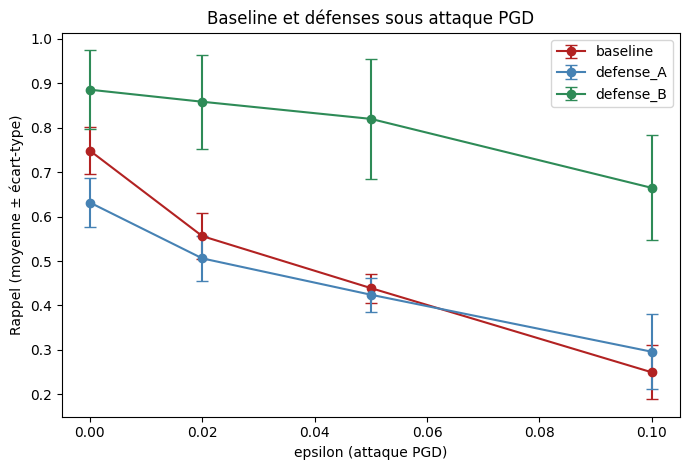

In [ ]:
# comparaison appariée (même graine) : défense moins baseline
base = df[df.modele == "baseline"].set_index("graine")
print("\n=== Gain de la défense sur le rappel (différence avec la baseline, même graine) ===")
for nom in ["defense_A", "defense_B"]:
    d_ = df[df.modele == nom].set_index("graine")
    for c in ["rappel_propre", "rappel_pgd_0.02", "rappel_pgd_0.05", "rappel_pgd_0.1"]:
        diff = (d_[c] - base[c]).dropna()
        print(f"{nom} | {c:<16} | {diff.mean():+.3f} ± {diff.std(ddof=1):.3f} | "
              f"meilleur que la baseline sur {(diff > 0).sum()}/{len(diff)} graines")

# rappel par type sous PGD 0.05
gt = pd.DataFrame(lignes_types)
tab = gt.pivot_table(index="type", columns="modele", values="rappel_pgd", aggfunc="mean")[NOMS]
tab["effectif"] = pd.Series(types_att).value_counts()
print("\n=== Rappel sous PGD (epsilon = 0.05) par type d'attaque, moyenne des graines ===")
print(tab.sort_values("effectif", ascending=False).round(3).to_string())

# figure
x = [0] + EPS_EVAL
plt.figure(figsize=(7, 4.8))
for nom, couleur in zip(NOMS, ["firebrick", "steelblue", "seagreen"]):
    d_ = df[df.modele == nom]
    m = [d_["rappel_propre"].mean()] + [d_[f"rappel_pgd_{e}"].mean() for e in EPS_EVAL]
    s = [d_["rappel_propre"].std(ddof=1)] + [d_[f"rappel_pgd_{e}"].std(ddof=1) for e in EPS_EVAL]
    plt.errorbar(x, m, yerr=s, marker="o", capsize=4, color=couleur, label=nom)
plt.xlabel("epsilon (attaque PGD)")
plt.ylabel("Rappel (moyenne ± écart-type)")
plt.title("Baseline et défenses sous attaque PGD")
plt.legend()
plt.tight_layout()
plt.savefig("defenses_pgd_multigraines.png", dpi=150)
plt.show()

# **9. Savoir si la défense B marche aussi sur des attaques qu’elle n’a jamais vues, et pas seulement sur celles qu’elle a déjà croisées pendant l’entraînement.**

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
dossier = "/content/drive/MyDrive/Mémoire_Master_Dataset/"
NB_GRAINES = 5
EPOQUES = 20
BATCH = 256
EPS_TRAIN = 0.05
EPS_EVAL = [0.05, 0.10]
LAMBDA = 1.0
K_MARGE = 3.0

In [ ]:
def famille_de(t):
    """Regroupe les types d'attaque en familles (Infiltration et Heartbleed : trop rares, on les écarte)."""
    t = str(t)
    if t.startswith("DoS"):
        return "DoS"
    if t == "DDoS":
        return "DDoS"
    if t == "PortScan":
        return "PortScan"
    if "Patator" in t:
        return "Patator"
    if t == "Bot":
        return "Bot"
    if t.startswith("Web Attack"):
        return "Web"
    return None


FAMILLES = ["DoS", "DDoS", "PortScan", "Patator", "Bot", "Web"]

In [ ]:
# --- données ---
f = np.load(dossier + "donnees_pretes.npz", allow_pickle=True)
X_train, X_val = f["X_train_normal"], f["X_val_normal"]
X_test, y_test, types = f["X_test"], f["y_test"], f["types_test"]
X_benin = X_test[y_test == 0]
X_att_tout = X_test[y_test == 1]
types_tout = types[y_test == 1]
fam_tout = np.array([famille_de(t) for t in types_tout], dtype=object)
nb_col = X_train.shape[1]

# même découpage 50/50 par type qu'à l'étape 8 (moitié pour entraîner, moitié pour évaluer)
rng0 = np.random.default_rng(0)
idx_tr, idx_ev = [], []
for t in np.unique(types_tout):
    idx = rng0.permutation(np.where(types_tout == t)[0])
    idx_tr += list(idx[:len(idx) // 2])
    idx_ev += list(idx[len(idx) // 2:])
garde_tr = [i for i in idx_tr if fam_tout[i] is not None]
garde_ev = [i for i in idx_ev if fam_tout[i] is not None]
X_att_tr, fam_tr = X_att_tout[garde_tr], fam_tout[garde_tr]
X_att_ev, fam_ev = X_att_tout[garde_ev], fam_tout[garde_ev]
for fam in FAMILLES:
    print(f"{fam:<9} entraînement : {(fam_tr == fam).sum():>6} | évaluation : {(fam_ev == fam).sum():>6}")

DoS       entraînement :  34173 | évaluation :  34177
DDoS      entraînement :  22527 | évaluation :  22528
PortScan  entraînement :  15929 | évaluation :  15929
Patator   entraînement :   1638 | évaluation :   1639
Bot       entraînement :    343 | évaluation :    343
Web       entraînement :    377 | évaluation :    379


In [ ]:
def construire_modele():
    entree = keras.Input(shape=(nb_col,))
    x = layers.Dense(64, activation="relu")(entree)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dense(16, activation="relu")(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dense(64, activation="relu")(x)
    sortie = layers.Dense(nb_col, activation="linear")(x)
    return keras.Model(entree, sortie)


def err_par_flux(modele, x):
    return tf.reduce_mean(tf.square(x - modele(x, training=False)), axis=1)


def pgd_tf(modele, x, eps, alpha, n_iter, signe):
    bas, haut = tf.minimum(x, 0.0), tf.maximum(x, 1.0)
    x_adv = x
    for _ in range(n_iter):
        with tf.GradientTape() as tape:
            tape.watch(x_adv)
            perte = tf.reduce_sum(err_par_flux(modele, x_adv))
        g = tf.sign(tape.gradient(perte, x_adv))
        x_adv = x_adv + signe * alpha * g
        x_adv = tf.clip_by_value(x_adv, x - eps, x + eps)
        x_adv = tf.clip_by_value(x_adv, bas, haut)
    return tf.stop_gradient(x_adv)


def entrainer(variante, graine, marge=None, familles_train=None):
    keras.backend.clear_session()
    keras.utils.set_random_seed(graine)
    modele = construire_modele()
    opt = keras.optimizers.Adam()

    if variante == "baseline":
        modele.compile(optimizer="adam", loss="mse")
        modele.fit(X_train, X_train, epochs=EPOQUES, batch_size=BATCH, verbose=0)
        return modele

    # attaques disponibles pour l'entraînement, tirées de façon ÉQUILIBRÉE entre familles
    dispo = np.isin(fam_tr, familles_train)
    X_dispo, fam_dispo = X_att_tr[dispo], fam_tr[dispo]
    poids = np.zeros(len(X_dispo))
    for fam in familles_train:
        masque = fam_dispo == fam
        poids[masque] = 1.0 / (len(familles_train) * masque.sum())

    def err_train(x):
        return tf.reduce_mean(tf.square(x - modele(x, training=True)), axis=1)

    @tf.function
    def pas_B(xb, xa):
        x_ev = pgd_tf(modele, xa, EPS_TRAIN, EPS_TRAIN / 2, 3, -1.0)
        with tf.GradientTape() as tape:
            perte = tf.reduce_mean(err_train(xb)) + LAMBDA * tf.reduce_mean(tf.nn.relu(marge - err_train(x_ev)))
        opt.apply_gradients(zip(tape.gradient(perte, modele.trainable_variables), modele.trainable_variables))

    rng = np.random.default_rng(graine)
    n = len(X_train)
    for _ in range(EPOQUES):
        ordre = rng.permutation(n)
        tirage = rng.choice(len(X_dispo), size=n, p=poids)
        for i in range(0, n - BATCH + 1, BATCH):
            pas_B(tf.constant(X_train[ordre[i:i + BATCH]]), tf.constant(X_dispo[tirage[i:i + BATCH]]))
    return modele


def evaluer(modele, familles):
    @tf.function
    def signe_gradient(x):
        with tf.GradientTape() as tape:
            tape.watch(x)
            perte = tf.reduce_sum(err_par_flux(modele, x))
        return tf.sign(tape.gradient(perte, x))

    def erreur(X):
        return np.mean((X - modele.predict(X, batch_size=4096, verbose=0)) ** 2, axis=1)

    def pgd(X, eps, alpha=0.005, n_iter=40, taille=8192):
        sortie = []
        for i in range(0, len(X), taille):
            x = tf.constant(X[i:i + taille])
            bas, haut = tf.minimum(x, 0.0), tf.maximum(x, 1.0)
            x_adv, meilleur, meilleure = x, x, err_par_flux(modele, x)
            for _ in range(n_iter):
                x_adv = x_adv - alpha * signe_gradient(x_adv)
                x_adv = tf.clip_by_value(x_adv, x - eps, x + eps)
                x_adv = tf.clip_by_value(x_adv, bas, haut)
                e = err_par_flux(modele, x_adv)
                mieux = e < meilleure
                meilleur = tf.where(mieux[:, None], x_adv, meilleur)
                meilleure = tf.where(mieux, e, meilleure)
            sortie.append(meilleur.numpy())
        return np.concatenate(sortie)

    seuil = np.percentile(erreur(X_val), 95)
    fp = (erreur(X_benin) > seuil).mean()
    res = []
    for fam in familles:
        Xf = X_att_ev[fam_ev == fam]
        ligne = {"famille": fam, "faux_positifs": fp, "rappel_propre": (erreur(Xf) > seuil).mean()}
        for eps in EPS_EVAL:
            ligne[f"rappel_pgd_{eps}"] = (erreur(pgd(Xf, eps)) > seuil).mean()
        res.append(ligne)
    return res, seuil

In [ ]:
# --- reprise automatique ---
f_res = dossier + "resultats_generalisation.csv"
lignes = pd.read_csv(f_res).to_dict("records") if os.path.exists(f_res) else []
deja = {int(l["graine"]) for l in lignes}
print("Graines déjà faites :", sorted(deja))

for graine in range(NB_GRAINES):
    if graine in deja:
        continue
    # 1) baseline (sans défense)
    modele = entrainer("baseline", graine)
    res, seuil_base = evaluer(modele, FAMILLES)
    lignes += [{"graine": graine, "modele": "baseline", **r} for r in res]
    marge = K_MARGE * seuil_base
    # 2) B qui connaît toutes les familles (échantillonnage équilibré)
    modele = entrainer("B", graine, marge, FAMILLES)
    res, _ = evaluer(modele, FAMILLES)
    lignes += [{"graine": graine, "modele": "B_famille_connue", **r} for r in res]
    # 3) B qui n'a JAMAIS vu la famille testée
    for fam in FAMILLES:
        modele = entrainer("B", graine, marge, [x for x in FAMILLES if x != fam])
        res, _ = evaluer(modele, [fam])
        lignes += [{"graine": graine, "modele": "B_famille_inconnue", **r} for r in res]
        print(f"graine {graine} | {fam:<9} inconnue : PGD 0.05 -> {res[0]['rappel_pgd_0.05']:.3f}")
    pd.DataFrame(lignes).to_csv(f_res, index=False)

Graines déjà faites : []
graine 0 | DoS       inconnue : PGD 0.05 -> 0.825
graine 0 | DDoS      inconnue : PGD 0.05 -> 0.517
graine 0 | PortScan  inconnue : PGD 0.05 -> 0.037
graine 0 | Patator   inconnue : PGD 0.05 -> 0.001
graine 0 | Bot       inconnue : PGD 0.05 -> 0.332
graine 0 | Web       inconnue : PGD 0.05 -> 0.005
graine 1 | DoS       inconnue : PGD 0.05 -> 0.523
graine 1 | DDoS      inconnue : PGD 0.05 -> 0.492
graine 1 | PortScan  inconnue : PGD 0.05 -> 0.004
graine 1 | Patator   inconnue : PGD 0.05 -> 0.002
graine 1 | Bot       inconnue : PGD 0.05 -> 0.000
graine 1 | Web       inconnue : PGD 0.05 -> 0.011
graine 2 | DoS       inconnue : PGD 0.05 -> 0.792
graine 2 | DDoS      inconnue : PGD 0.05 -> 0.651
graine 2 | PortScan  inconnue : PGD 0.05 -> 0.005
graine 2 | Patator   inconnue : PGD 0.05 -> 0.000
graine 2 | Bot       inconnue : PGD 0.05 -> 0.000
graine 2 | Web       inconnue : PGD 0.05 -> 0.000
graine 3 | DoS       inconnue : PGD 0.05 -> 0.790
graine 3 | DDoS      inco

In [ ]:
# --- résumé ---
df = pd.DataFrame(lignes)
MODELES = ["baseline", "B_famille_connue", "B_famille_inconnue"]
for colonne, titre in [("rappel_pgd_0.05", "PGD epsilon = 0.05"), ("rappel_propre", "sans attaque")]:
    moy = df.pivot_table(index="famille", columns="modele", values=colonne, aggfunc="mean")[MODELES].loc[FAMILLES]
    std = df.pivot_table(index="famille", columns="modele", values=colonne,
                         aggfunc=lambda s: s.std(ddof=1))[MODELES].loc[FAMILLES]
    tab = moy.round(3).astype(str) + " ± " + std.round(3).astype(str)
    print(f"\n=== Rappel par famille ({titre}), moyenne ± écart-type sur {df['graine'].nunique()} graines ===")
    print(tab.to_string())

print("\n=== Gain de B sur une famille INCONNUE (PGD 0.05, différence avec la baseline, même graine) ===")
b0 = df[df.modele == "baseline"].set_index(["graine", "famille"])["rappel_pgd_0.05"]
bi = df[df.modele == "B_famille_inconnue"].set_index(["graine", "famille"])["rappel_pgd_0.05"]
for fam in FAMILLES:
    d_ = (bi.xs(fam, level="famille") - b0.xs(fam, level="famille")).dropna()
    print(f"{fam:<9} | {d_.mean():+.3f} ± {d_.std(ddof=1):.3f} | "
          f"meilleur que la baseline sur {(d_ > 0).sum()}/{len(d_)} graines")


=== Rappel par famille (PGD epsilon = 0.05), moyenne ± écart-type sur 5 graines ===
modele         baseline B_famille_connue B_famille_inconnue
famille                                                    
DoS        0.77 ± 0.035    0.885 ± 0.054       0.702 ± 0.14
DDoS      0.254 ± 0.084    0.901 ± 0.106      0.605 ± 0.104
PortScan    0.003 ± 0.0    0.786 ± 0.433      0.011 ± 0.015
Patator       0.0 ± 0.0     0.737 ± 0.42      0.005 ± 0.007
Bot       0.008 ± 0.007    0.341 ± 0.266      0.066 ± 0.149
Web       0.001 ± 0.001    0.738 ± 0.394      0.017 ± 0.017

=== Rappel par famille (sans attaque), moyenne ± écart-type sur 5 graines ===
modele         baseline B_famille_connue B_famille_inconnue
famille                                                    
DoS       0.864 ± 0.013    0.937 ± 0.055      0.906 ± 0.029
DDoS       0.891 ± 0.07    0.952 ± 0.067       0.921 ± 0.06
PortScan  0.423 ± 0.092    0.825 ± 0.389      0.063 ± 0.096
Patator   0.084 ± 0.095    0.799 ± 0.321      0.188 ± 0.

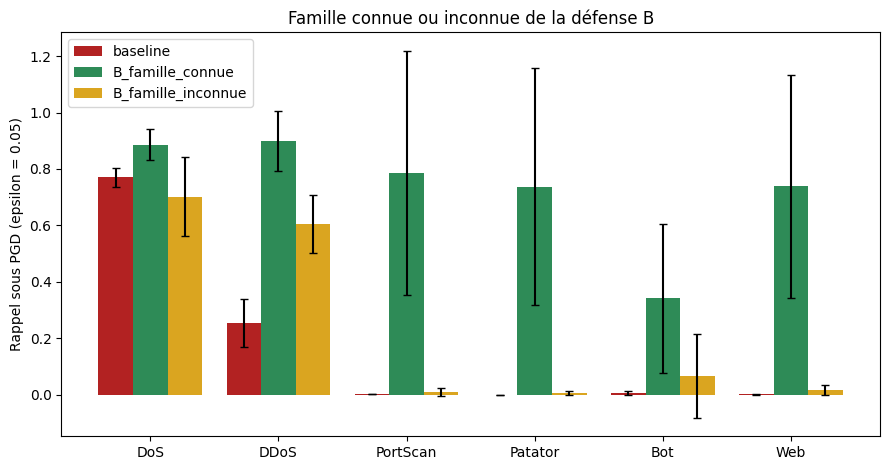

In [ ]:

# La Figure
fig, ax = plt.subplots(figsize=(9, 4.8))
largeur = 0.27
x = np.arange(len(FAMILLES))
for k, (nom, couleur) in enumerate(zip(MODELES, ["firebrick", "seagreen", "goldenrod"])):
    sous = df[df.modele == nom].groupby("famille")["rappel_pgd_0.05"]
    m = sous.mean().loc[FAMILLES]
    s = sous.std(ddof=1).loc[FAMILLES]
    ax.bar(x + (k - 1) * largeur, m, largeur, yerr=s, capsize=3, color=couleur, label=nom)
ax.set_xticks(x)
ax.set_xticklabels(FAMILLES)
ax.set_ylabel("Rappel sous PGD (epsilon = 0.05)")
ax.set_title("Famille connue ou inconnue de la défense B")
ax.legend()
plt.tight_layout()
plt.savefig("generalisation_defense_B.png", dpi=150)
plt.show()

In [ ]:
df = pd.read_csv(dossier + "resultats_generalisation.csv")
t = df[df.modele == "B_famille_connue"].pivot_table(
    index="famille", columns="graine", values="rappel_pgd_0.05")
print(t.round(2))

graine       0     1     2     3     4
famille                               
Bot       0.12  0.05  0.61  0.61  0.31
DDoS      0.91  0.74  1.00  1.00  0.86
DoS       0.88  0.81  0.95  0.92  0.86
Patator   0.96  0.00  0.97  0.99  0.76
PortScan  0.99  0.01  0.99  0.95  0.99
Web       0.89  0.04  0.90  0.98  0.89


graine 0 | 40 époques | DoS 0.85 DDoS 0.91 PortScan 0.02 Patator 0.96 Bot 0.02 Web 0.04
graine 1 | 40 époques | DoS 0.81 DDoS 0.79 PortScan 0.11 Patator 0.00 Bot 0.05 Web 0.01
graine 2 | 40 époques | DoS 0.96 DDoS 1.00 PortScan 1.00 Patator 0.97 Bot 0.61 Web 0.88
graine 3 | 40 époques | DoS 0.86 DDoS 0.92 PortScan 0.45 Patator 0.93 Bot 0.06 Web 0.04
graine 4 | 40 époques | DoS 0.87 DDoS 0.90 PortScan 0.98 Patator 0.76 Bot 0.48 Web 0.89
graine 5 | 20 époques | DoS 0.82 DDoS 0.67 PortScan 0.01 Patator 0.00 Bot 0.00 Web 0.04
graine 5 | 40 époques | DoS 0.87 DDoS 0.91 PortScan 0.37 Patator 0.00 Bot 0.24 Web 0.04
graine 6 | 20 époques | DoS 0.84 DDoS 0.89 PortScan 0.92 Patator 0.89 Bot 0.45 Web 0.04
graine 6 | 40 époques | DoS 0.85 DDoS 0.83 PortScan 0.50 Patator 0.00 Bot 0.18 Web 0.04
graine 7 | 20 époques | DoS 0.95 DDoS 1.00 PortScan 0.94 Patator 0.98 Bot 0.61 Web 0.92
graine 7 | 40 époques | DoS 0.90 DDoS 1.00 PortScan 1.00 Patator 0.96 Bot 0.58 Web 0.89
graine 8 | 20 époques | DoS 0.87

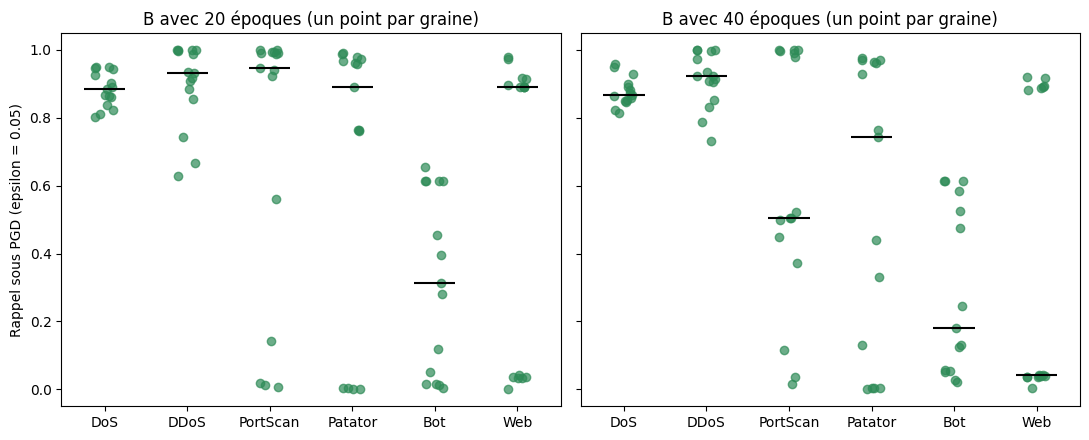

In [ ]:
# --- Étape 10 : stabilité de la défense B (à lancer après l'étape 9, dans la même session) ---
# Question : l'échec de la graine 1 est-il rare ? Un entraînement plus long le supprime-t-il ?
NB_GRAINES_10 = 15          # graines 0 à 14
EPOQUES_TESTEES = [20, 40]
SEUIL_REUSSITE = 0.5        # une famille est « protégée » si le rappel sous PGD 0.05 dépasse 0.5

f10 = dossier + "resultats_stabilite.csv"
lignes10 = pd.read_csv(f10).to_dict("records") if os.path.exists(f10) else []
deja10 = {(int(l["graine"]), int(l["epoques"])) for l in lignes10}

# les 5 premières graines à 20 époques ont déjà été faites à l'étape 9 : on les reprend telles quelles
etape9 = pd.read_csv(dossier + "resultats_generalisation.csv")
etape9 = etape9[etape9.modele == "B_famille_connue"]
for _, l in etape9.iterrows():
    if (int(l["graine"]), 20) not in deja10:
        lignes10.append({"graine": int(l["graine"]), "epoques": 20, "famille": l["famille"],
                         "rappel_propre": l["rappel_propre"], "rappel_pgd_0.05": l["rappel_pgd_0.05"]})
deja10 = {(int(l["graine"]), int(l["epoques"])) for l in lignes10}

for graine in range(NB_GRAINES_10):
    a_faire = [e for e in EPOQUES_TESTEES if (graine, e) not in deja10]
    if not a_faire:
        continue
    # la marge dépend du seuil de la baseline de cette graine (même calcul qu'à l'étape 9)
    EPOQUES = 20
    modele = entrainer("baseline", graine)
    _, seuil_base = evaluer(modele, FAMILLES[:1])
    marge = K_MARGE * seuil_base
    for ep in a_faire:
        EPOQUES = ep
        modele = entrainer("B", graine, marge, FAMILLES)
        res, _ = evaluer(modele, FAMILLES)
        lignes10 += [{"graine": graine, "epoques": ep, "famille": r["famille"],
                      "rappel_propre": r["rappel_propre"], "rappel_pgd_0.05": r["rappel_pgd_0.05"]} for r in res]
        pd.DataFrame(lignes10).to_csv(f10, index=False)
        print(f"graine {graine} | {ep} époques | " +
              " ".join(f"{r['famille']} {r['rappel_pgd_0.05']:.2f}" for r in res))
EPOQUES = 20

# --- résumé ---
d10 = pd.DataFrame(lignes10)
for ep in EPOQUES_TESTEES:
    sous = d10[(d10.epoques == ep) & (d10.graine < NB_GRAINES_10)]
    t = sous.pivot_table(index="famille", columns="graine", values="rappel_pgd_0.05").loc[FAMILLES]
    print(f"\n=== B, {ep} époques : rappel sous PGD 0.05, famille par famille et graine par graine ===")
    print(t.round(2).to_string())
    print(f"\n--- {ep} époques : résumé ---")
    for fam in FAMILLES:
        v = t.loc[fam].values
        print(f"{fam:<9} moyenne {v.mean():.3f} | médiane {np.median(v):.3f} | "
              f"protégée (> {SEUIL_REUSSITE}) sur {(v > SEUIL_REUSSITE).sum()}/{len(v)} graines")

# figure : un point par graine, trait noir = médiane
fig, axes = plt.subplots(1, len(EPOQUES_TESTEES), figsize=(11, 4.5), sharey=True)
for ax, ep in zip(axes, EPOQUES_TESTEES):
    sous = d10[(d10.epoques == ep) & (d10.graine < NB_GRAINES_10)]
    for k, fam in enumerate(FAMILLES):
        v = sous[sous.famille == fam]["rappel_pgd_0.05"].values
        ax.scatter(np.full(len(v), k) + np.random.default_rng(0).uniform(-0.12, 0.12, len(v)), v,
                   color="seagreen", alpha=0.7)
        ax.hlines(np.median(v), k - 0.25, k + 0.25, color="black")
    ax.set_xticks(range(len(FAMILLES)))
    ax.set_xticklabels(FAMILLES)
    ax.set_title(f"B avec {ep} époques (un point par graine)")
    ax.set_ylim(-0.05, 1.05)
axes[0].set_ylabel("Rappel sous PGD (epsilon = 0.05)")
plt.tight_layout()
plt.savefig("stabilite_defense_B.png", dpi=150)
plt.show()